# Python lab — Estimate, then detect
**IoT and Sensors for Energy**

**Author: Rasaq Oluwasegun DAMISA**

A building is monitored every **10 minutes** for 24 days (5 → 28 January 2026).
The file `building_24days.csv` contains:

| Column | Meaning |
|---|---|
| `time` | timestamp (10-min records) |
| `T_out_C` | outdoor temperature (°C) |
| `occupied` | 1 if the building is in use, 0 otherwise |
| `workday` | 1 Monday → Friday, 0 at the weekend |
| `P_kW` | measured electrical power (kW) |

**Your job, as in Chapter 4:**
1. **Estimate** — train an AI model that learns what *normal* power looks like (≈ 20 min).
2. **Detect** — use it to find an abnormal event on the last day, and evaluate the alarm (≈ 20 min).

Fill in every line marked `# TODO`. Run the cells from top to bottom (Shift + Enter).

> **Google Colab:** first upload `building_24days.csv` with the folder icon on the left.

## 0 · Load and look at the data (5 min)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv("../data/building_24days.csv", parse_dates=["time"])
df["hour"] = df["time"].dt.hour + df["time"].dt.minute / 60   # 13:20 -> 13.33
df.head()

,time,T_out_C,occupied,workday,P_kW,hour
0,2026-01-05 00:00:00,3.8,0,1,3.134,0.000000
1,2026-01-05 00:10:00,3.6,0,1,3.165,0.166667
2,2026-01-05 00:20:00,3.4,0,1,3.198,0.333333
3,2026-01-05 00:30:00,3.2,0,1,3.254,0.500000
4,2026-01-05 00:40:00,3.2,0,1,3.230,0.666667


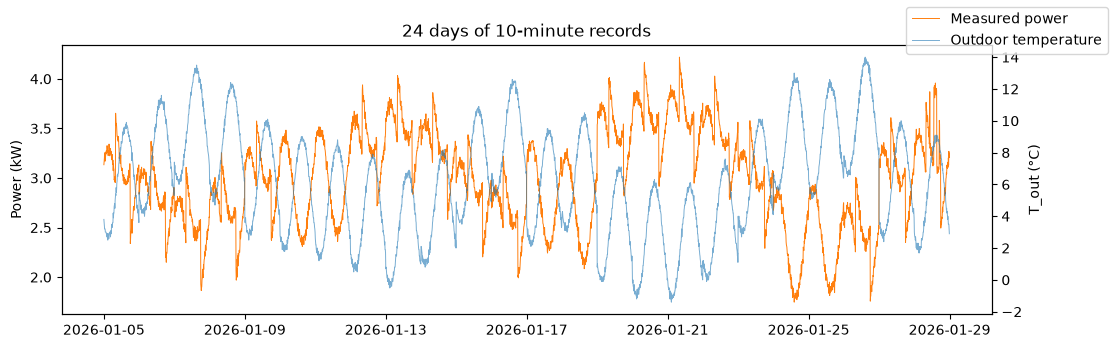

In [2]:
fig, ax1 = plt.subplots(figsize=(12, 3.5))
ax1.plot(df["time"], df["P_kW"], lw=0.7, color="tab:orange", label="Measured power")
ax1.set_ylabel("Power (kW)")
ax2 = ax1.twinx()
ax2.plot(df["time"], df["T_out_C"], lw=0.7, color="tab:blue", alpha=0.6, label="Outdoor temperature")
ax2.set_ylabel("T_out (°C)")
ax1.set_title("24 days of 10-minute records")
fig.legend(loc="upper right"); plt.show()

**Look first (1 min):** when is the power high? What happens at the weekends (10–11, 17–18, 24–25 Jan)?
When it is colder outside?

---
## Exercise 1 · Estimate normal power with an AI model (20 min)

### 1.1 Split the data **in time** — never shuffle

| Set | Days | Use |
|---|---|---|
| Train | 5 → 21 Jan (17 days) | fit the model |
| Validate | 22 → 27 Jan (6 days) | check the estimate, choose the threshold |
| Test | 28 Jan (1 day) | detect — open it only once |

In [3]:
train = df[df["time"] < "2026-01-22"]
                           

val = df[(df["time"] >= "2026-01-22") & (df["time"] < "2026-01-28")] # TODO: from 22 Jan (included) to 28 Jan (excluded)

test = df[(df["time"] >= "2026-01-28") & (df["time"] < "2026-01-29")].copy( ) # TODO: 28 Jan only

print(len(train), len(val), len(test), "records")   # expected: 2448 864 144

2448 864 144 records


### 1.2 Train the model

We use a **Random Forest**: many decision trees that each learn rules such as
*"if occupied and T_out < 5 °C, then P ≈ 4 kW"*, and average their answers.
It learns from **examples**: we give it the inputs `X` and the measured power `y` of the training days.

In [4]:
features = ["T_out_C", "occupied", "workday", "hour"]

model = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=0)
# TODO: train the model on the training days -> model.fit(inputs, target)

### 1.3 Estimate the validation week — days the model has never seen

The model **estimates** the normal power; we compare it with the meter.
Mean absolute error: $\text{MAE} = \dfrac{1}{N}\sum |P_\text{measured} - P_\text{estimated}|$.
One record lasts 10 min $= \tfrac{1}{6}$ h, so the energy is $E = \sum P \times \tfrac{1}{6}$ (kWh).

MAE = 0.030 kW
Energy: measured 400.2 kWh, estimated 401.4 kWh, error +0.3 %


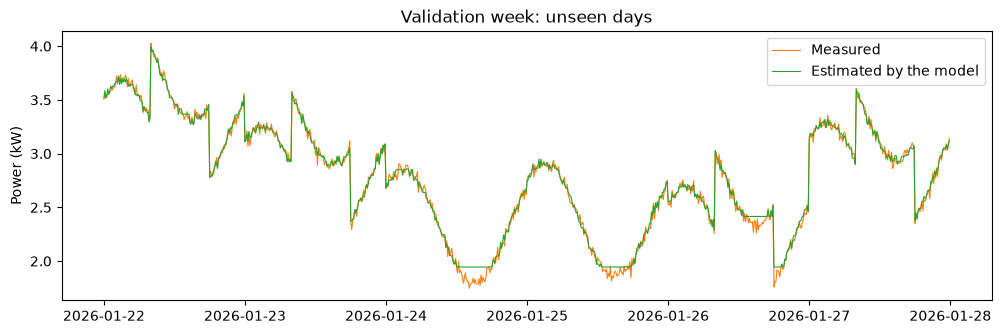

In [5]:
features = ["T_out_C", "occupied", "workday"]
model.fit(train[features], train["P_kW"])

P_est = model.predict(val[features])     # TODO: model.predict( ... ) on the validation days
r_val = val["P_kW"] - P_est              # residual = measured - estimated

MAE = r_val.abs().mean()                 # TODO: mean of the absolute residuals
E_meas = val["P_kW"].sum() / 6           # TODO: measured energy over the 6 days (kWh)
E_est = P_est.sum() / 6                  # TODO: estimated energy over the 6 days (kWh)

print(f"MAE = {MAE:.3f} kW")
print(f"Energy: measured {E_meas:.1f} kWh, estimated {E_est:.1f} kWh, error {100*(E_est-E_meas)/E_meas:+.1f} %")

plt.figure(figsize=(12, 3.5))
plt.plot(val["time"], val["P_kW"], lw=0.8, color="tab:orange", label="Measured")
plt.plot(val["time"], P_est, lw=0.8, color="tab:green", label="Estimated by the model")
plt.ylabel("Power (kW)"); plt.title("Validation week: unseen days"); plt.legend(); plt.show()

**Question 1.3:** is the estimate good enough to say what is *normal*? Where does the model make its largest errors?

### 1.4 Use the model as an estimator — "what if?"

Estimate the normal power on a workday at **2 °C**, (a) at 10:00 with the building occupied, (b) at 23:00, unoccupied.
Compare with the formula of the lecture: $P = 1.0 + 0.15\,\max(0, 18 - T_\text{out}) + 0.70 \times \text{occ}$.

In [6]:
cases = pd.DataFrame({"T_out_C": [2.0, 2.0], "occupied": [1, 0], "workday": [1, 1], "hour": [10.0, 23.0]})
cases["P_est_kW"] = model.predict(cases[features])                  # TODO: estimate with the model
cases["P_formula_kW"] = 1.0 + 0.15 * np.maximum(0, 18 - cases["T_out_C"]) + 0.70 * cases["occupied"]
cases.round(2)

,T_out_C,occupied,workday,hour,P_est_kW,P_formula_kW
0,2.0,1,1,10.0,4.13,4.1
1,2.0,0,1,23.0,3.40,3.4


**Bonus (if you are fast):** replace the Random Forest by `LinearRegression()` (from `sklearn.linear_model`)
and compare the MAE. Is the "AI" model always better than a simple one?

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

linear_model = LinearRegression()
linear_model.fit(train[features], train["P_kW"])

linear_pred = linear_model.predict(val[features])
forest_pred = model.predict(val[features])

linear_mae = mean_absolute_error(val["P_kW"], linear_pred)
forest_mae = mean_absolute_error(val["P_kW"], forest_pred)

print(f"Linear regression MAE: {linear_mae:.4f} kW")
print(f"Random Forest MAE:     {forest_mae:.4f} kW")

Linear regression MAE: 0.0239 kW
Random Forest MAE:     0.0304 kW


The linear regression model had a validation MAE of *0.0239 kW*, compared with *0.0304 kW* for the Random Forest using default settings and `random_state=42`. Linear regression therefore predicted building power slightly more accurately on the validation days.

A more complex model does not always perform better. Here, a simple linear model captured the relationship between outdoor temperature, occupancy, and power well enough to achieve a lower average prediction error.

---
## Exercise 2 · Detect the anomaly on the test day (20 min)

Same rule as in the lecture:
- **residual** $r = P_\text{measured} - P_\text{estimated}$
- **threshold** $\theta$ = largest residual on the validation days + 0.01 kW
- **persistence**: alarm only after **3 records in a row** with $r > \theta$

### 2.1 Choose the threshold on the validation days (not on the test day!)

In [8]:
theta = r_val.max() + 0.01                                # TODO: largest validation residual + 0.01
print(f"theta = {theta:.2f} kW")

theta = 0.10 kW


### 2.2 Residuals on the test day — 28 January

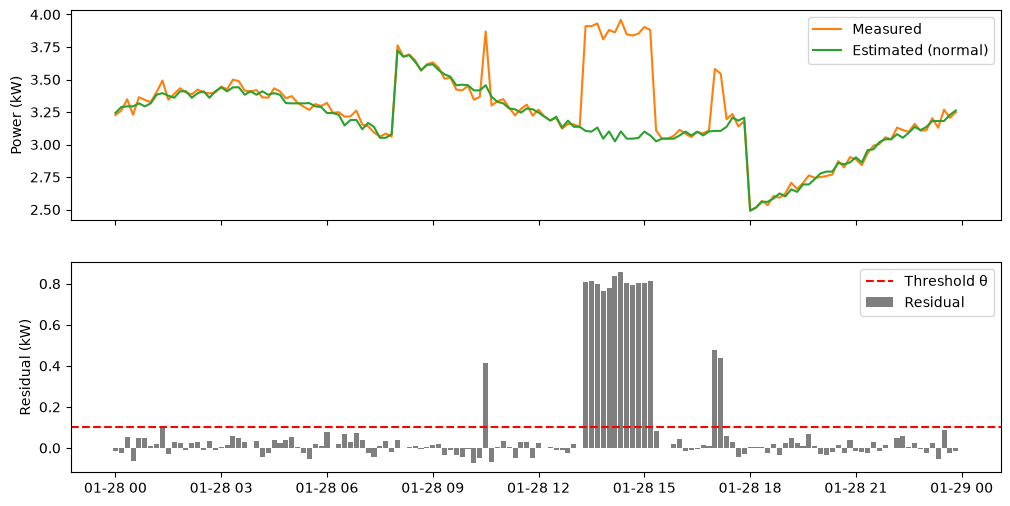

In [15]:
test["P_est"] = model.predict(test[features]) # TODO: estimate normal power on the test day
test["r"]     = test["P_kW"] - test["P_est"]  # TODO: residual = measured - estimated

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(test["time"], test["P_kW"], color="tab:orange", label="Measured")
ax[0].plot(test["time"], test["P_est"], color="tab:green", label="Estimated (normal)")
ax[0].set_ylabel("Power (kW)"); ax[0].legend()
ax[1].bar(test["time"], test["r"], width=0.006, color="tab:gray", label="Residual")
ax[1].axhline(theta, color="red", ls="--", label="Threshold θ")
ax[1].set_ylabel("Residual (kW)"); ax[1].legend()

from pathlib import Path

figure_dir = Path("../figure")
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / "test_day_anomaly.png", dpi=200, bbox_inches="tight")
plt.show()

**Question 2.2:** how many times does the residual go above θ? Do they all look like the same kind of event?

The plot shows *15 readings clearly above the threshold* on 28 January, grouped into *three events*.

- Around *10:30*, there is an isolated spike lasting one 10-minute reading.
- From about *13:20 to 15:10*, there are *12 consecutive readings* above the threshold, with measured power roughly *0.8 kW above* the normal estimate.
- Around *17:00*, there is a short spike spanning *two consecutive readings*.

The events differ in duration. The midday event is a sustained period of extra power use, while the morning and late-afternoon events are brief spikes.

### 2.3 Alarm with a persistence of 3

`above.rolling(3).sum()` counts how many of the last 3 records are above θ. The alarm is on when this count equals 3.

In [10]:
above = test["r"] > theta                                 # TODO: True when r > theta
test["alarm"] = above.rolling(3).sum() == 3               # TODO: True when the last 3 values of "above" are all True

print("Alarm starts at:", test.loc[test["alarm"], "time"].min())
print("Alarm ends at:  ", test.loc[test["alarm"], "time"].max())

Alarm starts at: 2026-01-28 13:40:00
Alarm ends at:   2026-01-28 15:10:00


### 2.4 Estimate the wasted energy

While the alarm is on, the residual is the extra power. Estimate the extra energy caught by the alarm (kWh).

In [11]:
E_extra = test.loc[test["alarm"], "r"].sum() / 6        # TODO: sum of the residuals while the alarm is on, x 1/6 h
print(f"Extra energy caught by the alarm: {E_extra:.2f} kWh")

Extra energy caught by the alarm: 1.34 kWh


### 2.5 Is the detector any good?

The maintenance log says: *heater left on from 13:20 to 15:20*. That is the truth for each 10-min interval.
$$\text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN}$$

In [12]:
truth = (test["time"] >= "2026-01-28 13:20") & (test["time"] < "2026-01-28 15:20")
alarm = test["alarm"]

TP = (alarm & truth).sum()                                    # TODO: alarm and truth
FP = (alarm & ~truth).sum()                                    # TODO: alarm and not truth  (use ~truth)
FN = (~alarm & truth).sum()                                    # TODO: no alarm (~alarm) and truth
TN = (~alarm & ~truth).sum()                                    # TODO: no alarm and not truth

print(f"TP={TP}  FP={FP}  FN={FN}  TN={TN}")
print(f"Precision = {TP/(TP+FP):.0%}   Recall = {TP/(TP+FN):.0%}")

TP=10  FP=0  FN=2  TN=132
Precision = 100%   Recall = 83%


Now compare persistence 1, 2 and 3 (run the cell, nothing to fill in):

I would choose a persistence of *3* for this building. It was the shortest setting that produced *zero false alarms* on the test day. It detected *10 of 12 heater-on intervals*, with a *20-minute delay*. A persistence of 4 added another 10 minutes of delay and reduced recall.

For a wind turbine, I would choose persistence based on the sampling interval and how quickly the fault needs to be detected. A fault that requires a faster response could justify a shorter delay.

In [13]:
rows = []
for k in [1, 2, 3, 4]:
    a = above.rolling(k).sum() == k
    tp, fp, fn = (a & truth).sum(), (a & ~truth).sum(), (~a & truth).sum()
    first = test.loc[a & truth, "time"].min()
    rows.append({"persistence": k, "TP": tp, "FP": fp, "FN": fn,
                 "precision": f"{tp/(tp+fp):.0%}", "recall": f"{tp/(tp+fn):.0%}",
                 "delay (min)": int((first - pd.Timestamp("2026-01-28 13:20")).total_seconds() / 60)})
pd.DataFrame(rows)

,persistence,TP,FP,FN,precision,recall,delay (min)
0,1,12,3,0,80%,100%,0
1,2,11,1,1,92%,92%,10
2,3,10,0,2,100%,83%,20
3,4,9,0,3,100%,75%,30


**Question 2.5:** which persistence would you choose for this building? Would you choose the same for a wind-turbine gearbox,
where a late alarm can mean a broken gearbox?

*For the building, I would choose a persistence of 3.* It was the shortest setting with zero false alarms on the test day. It achieved *100% precision* and *83% recall*, detecting the heater event after *20 minutes*. A persistence of 4 also produced zero false alarms but increased the delay to 30 minutes and reduced recall to 75%.

*For a wind-turbine gearbox, I would prioritize earlier detection.* If a late alarm could lead to gearbox damage, I would test a shorter persistence, such as *2 consecutive readings*, and use gearbox data to check whether it gives enough warning without producing too many false alarms. The actual delay depends on how often the sensor readings are evaluated.

---
### What to remember
- The AI model **estimates** what is normal; it is tested on days it has never seen.
- The **residual** says how far reality is from normal; the **written rule** (θ + persistence) turns it into an alarm.
- A detector is judged with **precision, recall and delay**, on unseen data.